# NeuroEmo fMRI — Digital Image Processing Capstone

## Emotion Recognition from Functional MRI

This notebook implements Digital Image Processing techniques on
4D fMRI data from the NeuroEmo dataset, followed by feature
extraction and emotion recognition.

### Dataset
- 40 subjects
- 5 emotional states
- Task: emotion elicitation (`task-fe`)
- fMRI data stored as NIfTI (`.nii.gz`)

In [2]:
import os
import json
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from pathlib import Path

print("Imports successful!")

Imports successful!


In [4]:
from pathlib import Path

# Project and dataset paths
PROJECT_DIR = Path(r"D:\coding\coding\projects\PROJECTS\Dip_capstone")
CODE_DIR = PROJECT_DIR / "code"
DATA_DIR = CODE_DIR / "data"

print("Project directory:")
print(PROJECT_DIR)

print("\nDataset directory:")
print(DATA_DIR)

print("\nDataset exists:", DATA_DIR.exists())

Project directory:
D:\coding\coding\projects\PROJECTS\Dip_capstone

Dataset directory:
D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data

Dataset exists: True


In [5]:
subjects = sorted(
    [p for p in DATA_DIR.glob("sub-*") if p.is_dir()]
)

print("Number of subjects:", len(subjects))

print("\nSubjects:")
for subject in subjects:
    print(subject.name)

Number of subjects: 40

Subjects:
sub-01
sub-02
sub-03
sub-04
sub-05
sub-06
sub-07
sub-08
sub-09
sub-10
sub-11
sub-12
sub-13
sub-14
sub-15
sub-16
sub-17
sub-18
sub-19
sub-20
sub-21
sub-22
sub-23
sub-24
sub-25
sub-26
sub-27
sub-28
sub-29
sub-30
sub-31
sub-32
sub-33
sub-34
sub-35
sub-36
sub-37
sub-38
sub-39
sub-40


In [6]:
structure_check = []

for subject in subjects:
    structure_check.append({
        "Subject": subject.name,
        "Anat": (subject / "anat").exists(),
        "Func": (subject / "func").exists()
    })

structure_df = pd.DataFrame(structure_check)

structure_df

,Subject,Anat,Func
0,sub-01,True,True
1,sub-02,True,True
2,sub-03,True,True
3,sub-04,True,True
4,sub-05,True,True
5,sub-06,True,True
6,sub-07,True,True
7,sub-08,True,True
8,sub-09,True,True
9,sub-10,True,True


In [7]:
fmri_files = []

for subject in subjects:
    func_dir = subject / "func"

    files = list(func_dir.glob("*_task-fe_bold.nii.gz"))

    fmri_files.append({
        "Subject": subject.name,
        "Task_fMRI_File": files[0].name if files else None,
        "Exists": len(files) > 0,
        "Size_MB": round(files[0].stat().st_size / (1024**2), 2)
                    if files else 0
    })

fmri_df = pd.DataFrame(fmri_files)

fmri_df

,Subject,Task_fMRI_File,Exists,Size_MB
0,sub-01,sub-01_task-fe_bold.nii.gz,True,97.57
1,sub-02,sub-02_task-fe_bold.nii.gz,True,98.39
2,sub-03,sub-03_task-fe_bold.nii.gz,True,93.97
3,sub-04,sub-04_task-fe_bold.nii.gz,True,97.62
4,sub-05,sub-05_task-fe_bold.nii.gz,True,97.00
5,sub-06,sub-06_task-fe_bold.nii.gz,True,96.85
6,sub-07,sub-07_task-fe_bold.nii.gz,True,104.15
7,sub-08,sub-08_task-fe_bold.nii.gz,True,101.63
8,sub-09,sub-09_task-fe_bold.nii.gz,True,91.41
9,sub-10,sub-10_task-fe_bold.nii.gz,True,103.35


In [8]:
print(
    "Task-fMRI files found:",
    fmri_df["Exists"].sum(),
    "/",
    len(fmri_df)
)

Task-fMRI files found: 40 / 40


In [9]:
dataset_info = []

for subject in subjects:

    fmri_path = (
        subject
        / "func"
        / f"{subject.name}_task-fe_bold.nii.gz"
    )

    img = nib.load(fmri_path)

    dataset_info.append({
        "Subject": subject.name,
        "Shape": img.shape,
        "Voxel_X": img.header.get_zooms()[0],
        "Voxel_Y": img.header.get_zooms()[1],
        "Voxel_Z": img.header.get_zooms()[2],
        "TR": img.header.get_zooms()[3]
    })

dataset_info_df = pd.DataFrame(dataset_info)

dataset_info_df

,Subject,Shape,Voxel_X,Voxel_Y,Voxel_Z,TR
0,sub-01,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
1,sub-02,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
2,sub-03,"(128, 128, 36, 200)",1.789827,1.789827,4.0,3.000001
3,sub-04,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
4,sub-05,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
5,sub-06,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
6,sub-07,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
7,sub-08,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
8,sub-09,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001
9,sub-10,"(128, 128, 36, 200)",1.796875,1.796875,4.0,3.000001


In [11]:
# Load one subject's complete 4D fMRI dataset

subject_id = "sub-01"

fmri_path = (
    DATA_DIR
    / subject_id
    / "func"
    / f"{subject_id}_task-fe_bold.nii.gz"
)

print("Loading:", fmri_path)

fmri_img = nib.load(fmri_path)

print("Shape:", fmri_img.shape)
print("Data type:", fmri_img.get_data_dtype())
print("Voxel size:", fmri_img.header.get_zooms()[:3])
print("TR:", fmri_img.header.get_zooms()[3])

Loading: D:\coding\coding\projects\PROJECTS\Dip_capstone\code\data\sub-01\func\sub-01_task-fe_bold.nii.gz
Shape: (128, 128, 36, 200)
Data type: int16
Voxel size: (1.796875, 1.796875, 4.0)
TR: 3.000001


In [13]:
fmri_data = fmri_img.get_fdata()

print("Data shape:", fmri_data.shape)
print("Data type:", fmri_data.dtype)
print("Minimum intensity:", fmri_data.min())
print("Maximum intensity:", fmri_data.max())
print("Mean intensity:", fmri_data.mean())
print("Standard deviation:", fmri_data.std())

volume_0 = fmri_data[:, :, :, 0]

print("3D volume shape:", volume_0.shape)

Data shape: (128, 128, 36, 200)
Data type: float64
Minimum intensity: 0.0
Maximum intensity: 132305.96348190308
Mean intensity: 7060.439963178646
Standard deviation: 15352.282345290087
3D volume shape: (128, 128, 36)


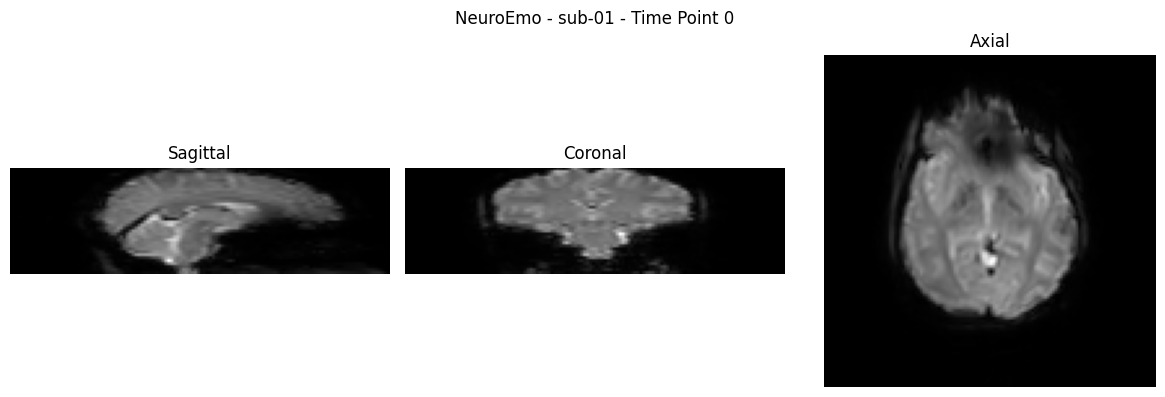

In [14]:
x = volume_0.shape[0] // 2
y = volume_0.shape[1] // 2
z = volume_0.shape[2] // 2

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(volume_0[x, :, :].T, cmap="gray", origin="lower")
plt.title("Sagittal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(volume_0[:, y, :].T, cmap="gray", origin="lower")
plt.title("Coronal")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(volume_0[:, :, z].T, cmap="gray", origin="lower")
plt.title("Axial")
plt.axis("off")

plt.suptitle("NeuroEmo - sub-01 - Time Point 0")
plt.tight_layout()
plt.show()

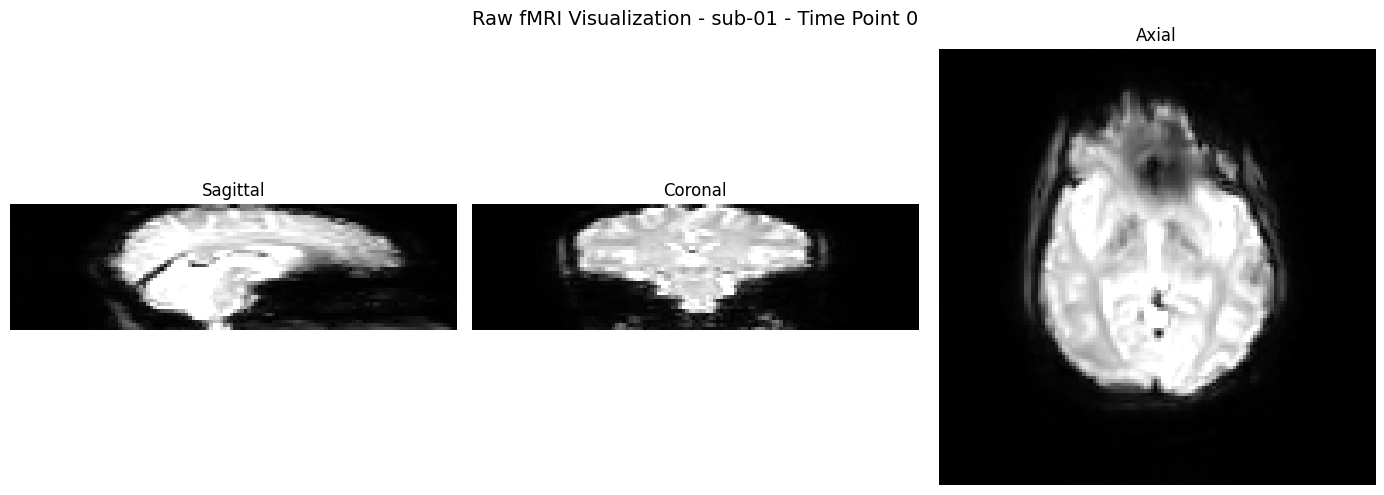

Display intensity range:
2nd percentile : 0.0
98th percentile: 53216.63787460327


In [15]:
# Display the middle slices with percentile-based intensity normalization

vmin = np.percentile(volume_0, 2)
vmax = np.percentile(volume_0, 98)

x = volume_0.shape[0] // 2
y = volume_0.shape[1] // 2
z = volume_0.shape[2] // 2

plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(
    volume_0[x, :, :].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
plt.title("Sagittal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    volume_0[:, y, :].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
plt.title("Coronal")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    volume_0[:, :, z].T,
    cmap="gray",
    origin="lower",
    vmin=vmin,
    vmax=vmax
)
plt.title("Axial")
plt.axis("off")

plt.suptitle(
    f"Raw fMRI Visualization - {subject_id} - Time Point 0",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Display intensity range:")
print("2nd percentile :", vmin)
print("98th percentile:", vmax)

In [16]:
# Histogram analysis - raw 4D fMRI

p1 = np.percentile(fmri_data, 1)
p25 = np.percentile(fmri_data, 25)
p50 = np.percentile(fmri_data, 50)
p75 = np.percentile(fmri_data, 75)
p99 = np.percentile(fmri_data, 99)

print("Raw fMRI Intensity Statistics")
print("-" * 40)
print(f"Minimum       : {fmri_data.min():.2f}")
print(f"1st percentile: {p1:.2f}")
print(f"25th percentile: {p25:.2f}")
print(f"Median        : {p50:.2f}")
print(f"75th percentile: {p75:.2f}")
print(f"99th percentile: {p99:.2f}")
print(f"Maximum       : {fmri_data.max():.2f}")
print(f"Mean          : {fmri_data.mean():.2f}")
print(f"Std deviation : {fmri_data.std():.2f}")

Raw fMRI Intensity Statistics
----------------------------------------
Minimum       : 0.00
1st percentile: 0.00
25th percentile: 35.88
Median        : 179.42
75th percentile: 2045.41
99th percentile: 56733.31
Maximum       : 132305.96
Mean          : 7060.44
Std deviation : 15352.28


In [17]:
zero_voxels = np.sum(fmri_data == 0)
total_voxels = fmri_data.size

zero_percentage = (zero_voxels / total_voxels) * 100

print("Background / Zero Intensity Analysis")
print("-" * 40)
print(f"Total voxels : {total_voxels:,}")
print(f"Zero voxels  : {zero_voxels:,}")
print(f"Zero percentage: {zero_percentage:.2f}%")

Background / Zero Intensity Analysis
----------------------------------------
Total voxels : 117,964,800
Zero voxels  : 11,266,923
Zero percentage: 9.55%


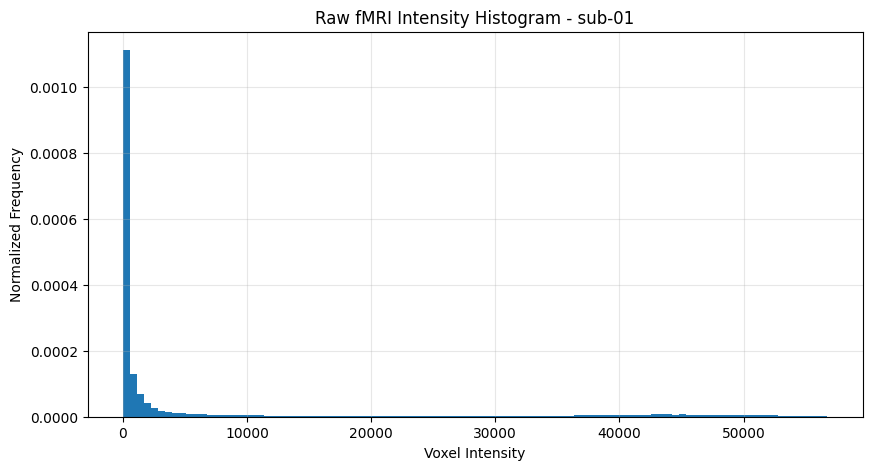

In [18]:
plt.figure(figsize=(10, 5))

display_max = np.percentile(fmri_data, 99)

plt.hist(
    fmri_data.flatten(),
    bins=100,
    range=(0, display_max),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Raw fMRI Intensity Histogram - sub-01")
plt.grid(alpha=0.3)

plt.show()

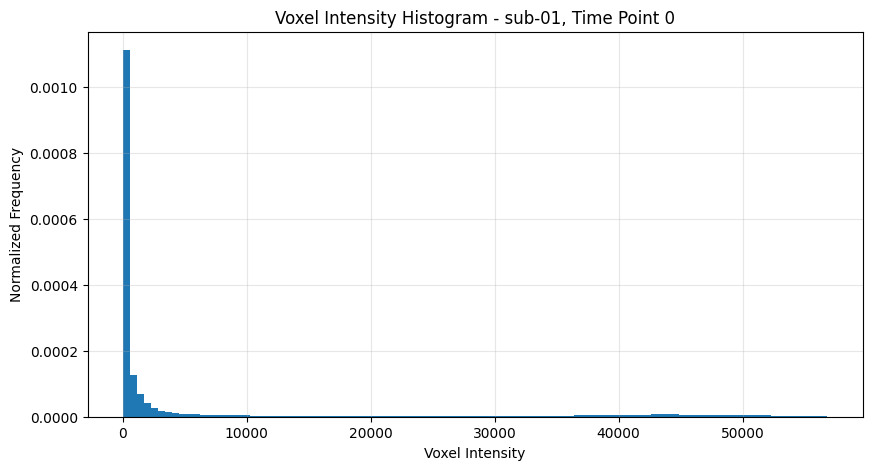

In [19]:
plt.figure(figsize=(10, 5))

volume_max = np.percentile(volume_0, 99)

plt.hist(
    volume_0.flatten(),
    bins=100,
    range=(0, volume_max),
    density=True
)

plt.xlabel("Voxel Intensity")
plt.ylabel("Normalized Frequency")
plt.title("Voxel Intensity Histogram - sub-01, Time Point 0")
plt.grid(alpha=0.3)

plt.show()